In [9]:
#Bai 1
import numpy as np
import pandas as pd
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report

# 1. Tải dữ liệu Breast Cancer
cancer = datasets.load_breast_cancer()
X = cancer.data
y = cancer.target

# 2. Chia dữ liệu và chuẩn hóa
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 3. Thực nghiệm với 4 loại kernel khác nhau
kernels = ['linear', 'poly', 'rbf', 'sigmoid']

print("--- KẾT QUẢ BÀI 1: SO SÁNH CÁC LOẠI KERNEL CỦA SVM ---")
for k in kernels:
    svm_model = SVC(kernel=k, C=1.0, gamma='scale', random_state=42)
    svm_model.fit(X_train, y_train)
    y_pred = svm_model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    print(f"Kernel = '{k:7s}' -> Độ chính xác (Accuracy): {acc:.4f}")

--- KẾT QUẢ BÀI 1: SO SÁNH CÁC LOẠI KERNEL CỦA SVM ---
Kernel = 'linear ' -> Độ chính xác (Accuracy): 0.9561
Kernel = 'poly   ' -> Độ chính xác (Accuracy): 0.8684
Kernel = 'rbf    ' -> Độ chính xác (Accuracy): 0.9825
Kernel = 'sigmoid' -> Độ chính xác (Accuracy): 0.9561


In [10]:
#Bai 2
import numpy as np
from sklearn import datasets
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report

# 1. Tải và chuẩn hóa dữ liệu
cancer = datasets.load_breast_cancer()
X_train, X_test, y_train, y_test = train_test_split(cancer.data, cancer.target, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 2. Định nghĩa lưới siêu tham số (Parameter Grid) cần thử nghiệm
param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': ['scale', 'auto', 0.1, 0.01, 0.001],
    'kernel': ['rbf', 'linear', 'poly']
}

# 3. Khởi tạo và chạy GridSearchCV (cv=5 chia 5 phần để kiểm thử chéo)
grid = GridSearchCV(estimator=SVC(), param_grid=param_grid, cv=5, scoring='accuracy', verbose=1)
grid.fit(X_train, y_train)

# 4. In ra bộ siêu tham số tốt nhất và đánh giá trên tập kiểm tra
print("\n--- KẾT QUẢ BÀI 2: TỐI ƯU SIÊU THAM SỐ VỚI GRIDSEARCHCV ---")
print(f"Bộ siêu tham số tối ưu nhất: {grid.best_params_}")
print(f"Độ chính xác trung bình trên tập Train (CV): {grid.best_score_:.4f}")

# Sử dụng mô hình tốt nhất để dự đoán trên tập Test
best_svm = grid.best_estimator_
y_pred = best_svm.predict(X_test)

print(f"Độ chính xác trên tập Test: {accuracy_score(y_test, y_pred):.4f}")
print("Báo cáo phân loại chi tiết:")
print(classification_report(y_test, y_pred, target_names=cancer.target_names))

Fitting 5 folds for each of 60 candidates, totalling 300 fits

--- KẾT QUẢ BÀI 2: TỐI ƯU SIÊU THAM SỐ VỚI GRIDSEARCHCV ---
Bộ siêu tham số tối ưu nhất: {'C': 1, 'gamma': 'scale', 'kernel': 'rbf'}
Độ chính xác trung bình trên tập Train (CV): 0.9758
Độ chính xác trên tập Test: 0.9825
Báo cáo phân loại chi tiết:
              precision    recall  f1-score   support

   malignant       1.00      0.95      0.98        43
      benign       0.97      1.00      0.99        71

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



--- KẾT QUẢ BÀI 3: PHÂN LOẠI CHỮ SỐ VIẾT TAY (DIGITS) ---
Mô hình KNN (K=5)            -> Độ chính xác (Accuracy): 0.9750
Mô hình SVM (kernel='poly')  -> Độ chính xác (Accuracy): 0.9639
Mô hình SVM (kernel='rbf')   -> Độ chính xác (Accuracy): 0.9806


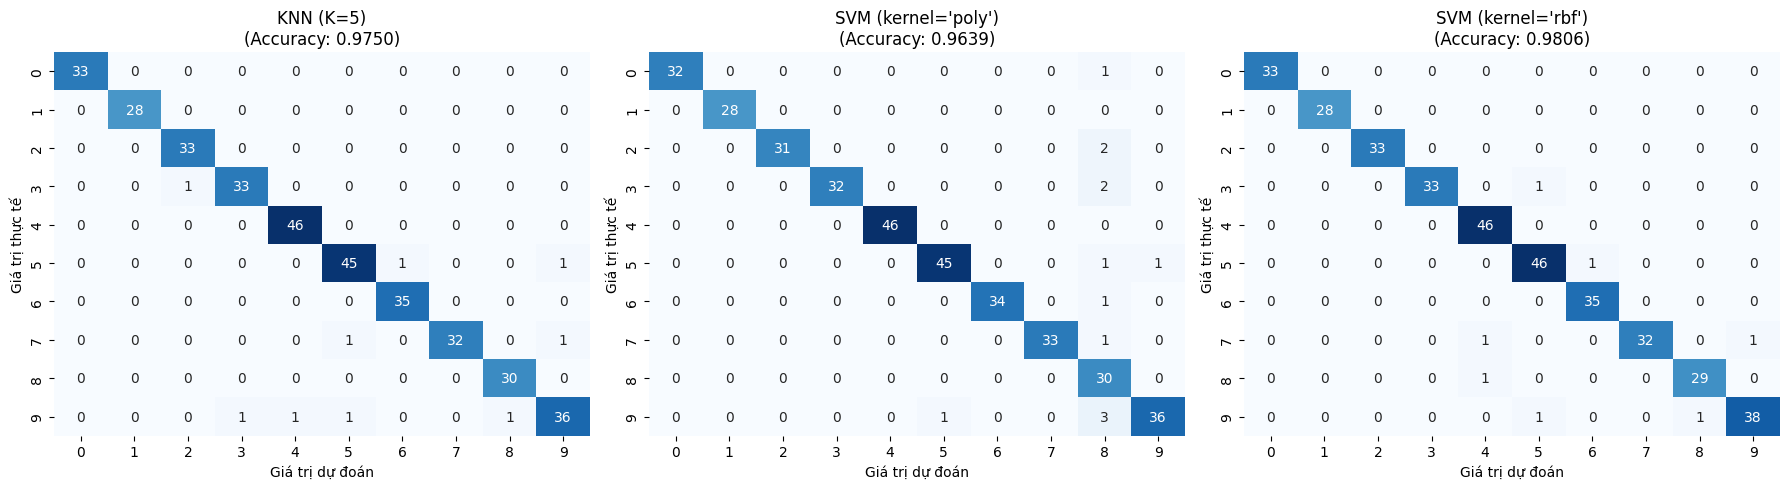

In [11]:
#Bai 3
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 1. Tải tập dữ liệu Digits
digits = load_digits()
X = digits.data    # 64 đặc trưng (điểm ảnh 8x8)
y = digits.target  # 10 nhãn chữ số (từ 0 đến 9)

# 2. Phân chia dữ liệu (80% train, 20% test) và chuẩn hóa
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Huấn luyện lần lượt 3 mô hình: KNN, SVM (poly), SVM (rbf)
models = {
    "KNN (K=5)": KNeighborsClassifier(n_neighbors=5),
    "SVM (kernel='poly')": SVC(kernel='poly', C=1.0, degree=3),
    "SVM (kernel='rbf')": SVC(kernel='rbf', C=1.0, gamma='scale')
}

results = {}
conf_matrices = {}

print("--- KẾT QUẢ BÀI 3: PHÂN LOẠI CHỮ SỐ VIẾT TAY (DIGITS) ---")
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)

    acc = accuracy_score(y_test, y_pred)
    results[name] = acc
    conf_matrices[name] = confusion_matrix(y_test, y_pred)

    print(f"Mô hình {name:20s} -> Độ chính xác (Accuracy): {acc:.4f}")

# 4. Hiển thị Ma trận nhầm lẫn của cả 3 mô hình để so sánh trực quan
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, cm) in zip(axes, conf_matrices.items()):
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=digits.target_names, yticklabels=digits.target_names)
    ax.set_title(f"{name}\n(Accuracy: {results[name]:.4f})")
    ax.set_xlabel("Giá trị dự đoán")
    ax.set_ylabel("Giá trị thực tế")

plt.tight_layout()
plt.show()